# SLID and a simulated location–scale shift: mboostrs against classical and ML competitors

This is one benchmark study of `mboostrs`, graded on the knowledge-discovery
scorecard `mboostrs-scorecard/2.1`. It runs two data arms and keeps them
separate throughout.

- **`slid`** — the real `carData::SLID` wage survey (Ontario 1994). Rows with a
  missing `wages` or `education` are dropped; `language` nulls become an
  `Unknown` level. The response is `log(wages)` and the covariates are
  `education`, `age`, `sex`, `language`.
- **`sim`** — a simulated location–scale shift with planted truth, fixed in
  `slid_lss_sim/answer_key.md` before any run. The location has a nonlinear
  `x1`, a quadratic `x2`, a main `g` effect and an `x3`-by-`g` interaction; the
  log-scale is linear in `x5`; `x6`, `x7`, `x8` are nuisance.

Ten random 50/50 train/test splits per arm (seeds 0–9). Every arm, seed and
method sees the same rows.

The full battery, settings and caveats are in
`slid_lss_sim/findings.md` and `slid_lss_sim/friction.md`. The run artefacts are
`slid_lss_sim/results.parquet`, `slid_lss_sim/provenance.json`,
`slid_lss_sim/evidence.json` and `slid_lss_sim/scores.json`.



## The two mboostrs tracks

- **Known specification.** mboostrs is handed the true structure (the answer-key
  formula on `sim`, a literature specification on `slid`) and fits it with
  `mb.gamboostLSS` and a cross-validated `mstop`. This measures estimation and
  calibration.
- **Discovery.** mboostrs receives only the data and the response name and calls
  `mb.discover`, which chooses the family, formula and spread model itself. This
  measures finding the structure.

## The competitors

Competitors receive only the data in both tracks, never the structure, and all
settings are defaults unless noted. They are: a two-stage OLS with spline terms
(`statsmodels_2stage`), pyGAM with the same two-stage scale (`pygam_2stage`),
LightGBM mean and quantile (`lightgbm`, `lightgbm_quantile`), XGBoost
(`xgboost`), sklearn histogram gradient boosting (`histgb`), CatBoost with
`RMSEWithUncertainty` and quantile versions (`catboost_uncertainty`,
`catboost_quantile`), EBM (`ebm`) and APLR (`aplr`).

Two notes. Methods that model a mean only get a homoscedastic Gaussian built
from the training residuals, for CRPS and the log score. The classical
GAMLSS-style spline model (`statsmodels_gamlss_known`) is also given the true
formula, so it is a known-specification comparator and is reported next to
mboostrs rather than counted among the data-only competitors.

The EBM defaults were unusably slow at this size, so EBM runs with
`interactions=10, outer_bags=4, max_bins=256`. That is a stated deviation.

The primary loss is the Gaussian CRPS (continuous ranked probability score: a score of the whole predictive distribution against the observed value; lower is better). The best competitor is chosen on the test
loss for each seed, so it is a retrospective best, not a prespecified baseline.
The gap is mboostrs minus that best competitor, in percent, paired across the
ten seeds. Negative means mboostrs is better.

In [1]:
from pathlib import Path
import json

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

STUDY = Path("slid_lss_sim")
res = pl.read_parquet(STUDY / "results.parquet")
ev = json.loads((STUDY / "evidence.json").read_text())
sc = json.loads((STUDY / "scores.json").read_text())
prov = json.loads((STUDY / "provenance.json").read_text())

print("row count:", res.height)
print("mboostrs", prov["mboostrs_version"],
      "declared", prov["mboostrs_build_sha_declared"],
      "build git_revision", prov["mboostrs_build_info_git_revision"][:12])
print("methods:", sorted(res["method"].unique().to_list()))
res.group_by(["arm", "seed"]).len().group_by("arm").agg(pl.len()).sort("arm")

row count: 260
mboostrs 0.1.3 declared 0ae6f81d build git_revision 65f71c769e86
methods: ['aplr', 'catboost_quantile', 'catboost_uncertainty', 'ebm', 'histgb', 'lightgbm', 'lightgbm_quantile', 'mb_discover', 'mb_lss_known', 'pygam_2stage', 'statsmodels_2stage', 'statsmodels_gamlss_known', 'xgboost']


arm,len
str,u32
"""sim""",10
"""slid""",10


## Primary result: gap to the best competitor

Each row is one mboostrs track on one arm. The best competitor is the
data-only method with the lowest test CRPS on that seed; its name is not fixed
across seeds, because each seed's test CRPS determines the reference.

In [2]:
MB = ["mb_lss_known", "mb_discover"]


def gap_table(arm, loss):
    d = res.filter(pl.col("arm") == arm)
    best = (d.filter(pl.col("track") == "competitor").sort(loss)
            .group_by("seed", maintain_order=True).first()
            .select("seed", pl.col(loss).alias("best")))
    j = d.join(best, on="seed").with_columns(
        (100 * (pl.col(loss) / pl.col("best") - 1)).alias("gap"))
    out = (j.filter(pl.col("method").is_in(MB))
           .group_by("method")
           .agg(pl.col("gap").mean().alias("gap_pct"),
                (pl.col("gap").std() / pl.len().sqrt()).alias("se"))
           .sort("gap_pct"))
    return out


gap_rows = []
LABEL = {"mb_lss_known": "known spec", "mb_discover": "discovery"}
for arm in ("sim", "slid"):
    for loss in ("crps", "rmse"):
        g = gap_table(arm, loss)
        for r in g.to_dicts():
            gap_rows.append({"arm": arm, "loss": loss,
                             "track": LABEL[r["method"]],
                             "gap_pct": round(r["gap_pct"], 2),
                             "se_pct": round(r["se"], 2)})
gap_tbl = pl.DataFrame(gap_rows)
gap_tbl

arm,loss,track,gap_pct,se_pct
str,str,str,f64,f64
"""sim""","""crps""","""known spec""",-4.56,0.16
"""sim""","""crps""","""discovery""",-4.44,0.16
"""sim""","""rmse""","""known spec""",-1.02,0.14
"""sim""","""rmse""","""discovery""",-0.99,0.14
"""slid""","""crps""","""known spec""",0.58,0.13
"""slid""","""crps""","""discovery""",34.07,0.47
"""slid""","""rmse""","""known spec""",0.75,0.13
"""slid""","""rmse""","""discovery""",28.76,0.42


In [3]:
# which competitor was selected per seed, per arm
sel = {}
for arm in ("sim", "slid"):
    d = res.filter(pl.col("arm") == arm)
    pick = (d.filter(pl.col("track") == "competitor").sort("crps")
            .group_by("seed", maintain_order=True).first())
    sel[arm] = pick.group_by("method").len().sort("len", descending=True).to_dicts()
sel

{'sim': [{'method': 'statsmodels_2stage', 'len': 6},
  {'method': 'ebm', 'len': 3},
  {'method': 'catboost_quantile', 'len': 1}],
 'slid': [{'method': 'aplr', 'len': 9}, {'method': 'ebm', 'len': 1}]}

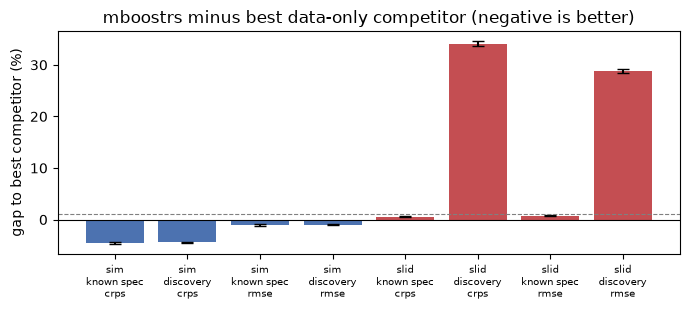

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
labels = [f"{r['arm']}\n{r['track']}\n{r['loss']}" for r in gap_rows]
vals = [r["gap_pct"] for r in gap_rows]
errs = [r["se_pct"] for r in gap_rows]
colors = ["#4c72b0" if v <= 0 else "#c44e52" for v in vals]
ax.bar(range(len(vals)), vals, yerr=errs, capsize=4, color=colors)
ax.axhline(0, color="black", lw=0.8)
ax.axhline(1, color="grey", ls="--", lw=0.8)
ax.set_xticks(range(len(vals)))
ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel("gap to best competitor (%)")
ax.set_title("mboostrs minus best data-only competitor (negative is better)")
plt.tight_layout()
plt.show()

On `sim`, mboostrs beats the best data-only competitor in both tracks: about
4.6% lower CRPS for the known specification and 4.4% for discovery, with a
standard error near 0.16 percentage points. Both are well outside their standard
errors. On `slid` the known specification sits about 0.6% above the best
competitor (SE 0.13), inside the 1% goal but not ahead. Discovery on `slid` is
34% worse, and this is the largest gap in the study.

The two arms pull in opposite directions because the response is different. The
simulated response is continuous and can be negative, so discovery infers a
Gaussian family and the noise model matches the data. The real response,
`log(wages)`, is strictly positive, and that triggers a different family choice
in `mb.discover` (see SLID family selection).

(every-method-up-close)=
## Scores for every method

The table below gives the mean Gaussian CRPS, RMSE and 95% coverage for every
method on both arms. It is the raw material for the gap table. Lower CRPS and
RMSE are better; 95% coverage should be near 0.95.

In [5]:
up = (res.group_by(["arm", "method"])
      .agg(pl.col("crps").mean().alias("crps"),
           pl.col("rmse").mean().alias("rmse"),
           pl.col("coverage95").mean().alias("cov95"),
           pl.col("coverage80").mean().alias("cov80"))
      .sort(["arm", "crps"]))
up.with_columns(
    pl.col("crps").round(4), pl.col("rmse").round(4),
    pl.col("cov95").round(3), pl.col("cov80").round(3))

arm,method,crps,rmse,cov95,cov80
str,str,f64,f64,f64,f64
"""sim""","""mb_lss_known""",0.6154,1.1761,0.948,0.798
"""sim""","""mb_discover""",0.6162,1.1764,0.956,0.816
"""sim""","""statsmodels_gamlss_known""",0.6194,1.1809,0.947,0.798
"""sim""","""statsmodels_2stage""",0.646,1.2169,0.944,0.792
"""sim""","""ebm""",0.6475,1.1882,0.929,0.812
…,…,…,…,…,…
"""slid""","""lightgbm_quantile""",0.2238,0.3998,0.884,0.705
"""slid""","""histgb""",0.2257,0.4059,0.897,0.728
"""slid""","""lightgbm""",0.2258,0.4063,0.896,0.729


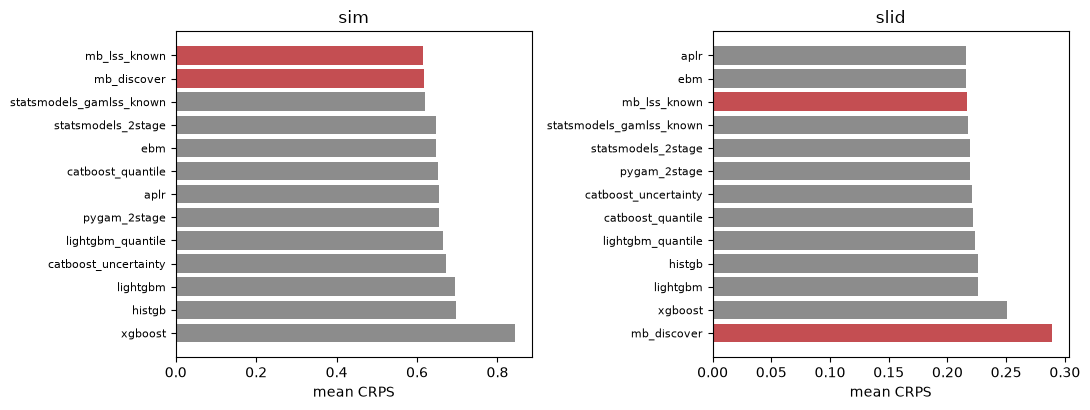

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=False)
for ax, arm in zip(axes, ("sim", "slid")):
    d = (res.filter(pl.col("arm") == arm).group_by("method")
         .agg(pl.col("crps").mean().alias("crps")).sort("crps"))
    names = d["method"].to_list()
    vals = d["crps"].to_numpy()
    cols = ["#c44e52" if n.startswith("mb_") else "#8c8c8c" for n in names]
    ax.barh(range(len(names)), vals, color=cols)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("mean CRPS")
    ax.set_title(arm)
plt.tight_layout()
plt.show()

On `sim`, the mean CRPS differences are small: the
classical two-stage spline model (`statsmodels_2stage`) and EBM are close
behind mboostrs, while the tree ensembles with a residual Gaussian
(`lightgbm`, `histgb`, `xgboost`) are further back, mostly because a single
constant sigma poorly matches a response whose spread genuinely grows with
`x5`. On `slid`, the leading methods have similar CRPS: APLR leads on nine seeds, with EBM
on the tenth, and mboostrs' known specification is level with them. Discovery
is the outlier, at the far right, because it returns an intercept-only model.

## Simulated arm: what each method recovered

The simulated arm carries planted truth, so recovery can be measured directly.
`D1a` compares the fitted mean and log-scale to the truth on test rows and
checks the recovered `x3` slopes by `g`. `D1b` scores the discovery track's term
selection.

In [7]:
def d1a_table():
    rows = []
    for m in ("mb_lss_known", "statsmodels_gamlss_known"):
        d = res.filter((pl.col("arm") == "sim") & (pl.col("method") == m))
        rows.append({
            "method": m,
            "rmse_mu": round(d["rmse_mu"].mean(), 4),
            "rmse_log_sigma": round(d["rmse_log_sigma"].mean(), 4),
            "slope_a": round(d["slope_a"].mean(), 3),
            "slope_b": round(d["slope_b"].mean(), 3),
            "slope_c": round(d["slope_c"].mean(), 3),
        })
    return pl.DataFrame(rows)


d1a_table()

method,rmse_mu,rmse_log_sigma,slope_a,slope_b,slope_c
str,f64,f64,f64,f64,f64
"""mb_lss_known""",0.0563,0.014,0.0,1.458,-1.035
"""statsmodels_gamlss_known""",0.1227,0.0433,-0.029,1.531,-0.945


In [8]:
# D1b: selections come from evidence.json (normalised term names)
sel_rows = []
for r in ev["arms"]["sim"]["d1b"]["selections"]:
    sel_rows.append({"seed": r["seed"], "family": r["family_discovered"],
                     "location": r["loc_sel"], "scale": r["scale_sel"]})
pl.DataFrame(sel_rows)

seed,family,location,scale
i64,str,str,str
0,"""Gaussian""","""g,g:x3,x1,x2""","""x5"""
1,"""Gaussian""","""g,g:x3,x1,x2""","""x5"""
2,"""Gaussian""","""g,g:x3,x1,x2""","""x5"""
3,"""Gaussian""","""g,g:x3,x1,x2""","""x5"""
4,"""Gaussian""","""g,g:x3,x1,x2""","""x5"""
5,"""Gaussian""","""g,g:x3,x1,x2""","""x5"""
6,"""Gaussian""","""g,g:x3,x1,x2""","""x5"""
7,"""Gaussian""","""g,g:x3,x1,x2,x3""","""x5"""
8,"""Gaussian""","""g,g:x3,x1,x2""","""x5"""


In [9]:
tot = ev["arms"]["sim"]["d1b"]["totals"]
d1b = ev["arms"]["sim"]["d1b"]
pl.DataFrame([{
    "loc_precision": round(d1b["loc_precision"]["mean"], 3),
    "loc_recall": round(d1b["loc_recall"]["mean"], 3),
    "scale_precision": round(d1b["scale_precision"]["mean"], 3),
    "scale_recall": round(d1b["scale_recall"]["mean"], 3),
    "x3g_found_seeds": tot["loc_interaction_seeds"],
    "false_nuisance": tot["false_nuisance_total"],
    "x5_in_location_seeds": tot["trap_x5_in_loc_seeds"],
    "active_in_scale_seeds": tot["trap_active_in_scale_seeds"],
}
])

loc_precision,loc_recall,scale_precision,scale_recall,x3g_found_seeds,false_nuisance,x5_in_location_seeds,active_in_scale_seeds
f64,f64,f64,f64,i64,i64,i64,i64
0.98,1.0,1.0,1.0,10,0,0,0


On `sim` the known-specification fit recovers the mean to an RMSE of about
0.056 and the log-scale to about 0.014, roughly half the error of the classical
GAMLSS-style comparator, and the `x3` slopes are within about 0.04 of the truth
(1.5 and −1.0). Discovery does almost as well: it selects `x1`, `x2`, `g` and
the `x3`×`g` interaction in every seed, `x5` as the scale driver with perfect
precision and recall, and never once picks a nuisance (`x6`, `x7`, `x8`) or the
traps (`x5` in location, the location variables in scale). One seed additionally
keeps an `x3` main effect, which is why location precision is 0.98 rather than
1.

The selected terms recover the planted structure on `sim`. On `slid`, the
intercept-only result follows from family selection, (see SLID family selection).

(why-discovery-collapses-on-slid)=
## SLID family selection

`mb.discover` does not raise on SLID. It returns `y ~ 1`, the intercept-only
model, on all ten seeds.

`log(wages)` is strictly positive, so `mb.autospec`'s family probe (the check that chooses between a Gamma and a Gaussian family) recommends `GammaReg`. The probe can replace a Gamma with a Gaussian, but only when it is
allowed to run its squared-error comparison, and the discovery path does not
give it that budget. The boosted Gamma then fails to descend — the run warns
that the training risk rose on 101 of 200 steps because the step `nu=0.1` is
too large for that loss — and with a non-descending path the backward elimination (removal of terms one at a time) sees no term as useful, so it drops them all.

The family validation runs only when the search budget is at least six times the number of folds. The discovery path calls the search with a budget of 0, so the validation does not run. Forcing the family shows what the search could find:
`mb.discover(..., family=mb.Gaussian())` recovers
`bbs(education) + bbs(age) + bols(sex) + bbs(age, by=sex)` with test RMSE about
0.40, against about 0.51 for the Gamma pick and 0.40 for the known
specification. Supplying Gaussian therefore restores useful term selection on this dataset.

The weakness, its numbers and its proposed fix are in
`slid_lss_sim/findings.md` (findings 1 and 2).

## Calibration

Coverage and width for the two mboostrs tracks. Nominal coverage is 0.80 and
0.95.

In [10]:
cov_rows = []
for arm in ("sim", "slid"):
    for m in MB:
        d = res.filter((pl.col("arm") == arm) & (pl.col("method") == m))
        cov_rows.append({
            "arm": arm, "track": m, "cov80": round(d["coverage80"].mean(), 3),
            "width80": round(d["width80"].mean(), 3),
            "cov95": round(d["coverage95"].mean(), 3),
            "width95": round(d["width95"].mean(), 3)})
pl.DataFrame(cov_rows)

arm,track,cov80,width80,cov95,width95
str,str,f64,f64,f64,f64
"""sim""","""mb_lss_known""",0.798,2.763,0.948,4.226
"""sim""","""mb_discover""",0.816,2.859,0.956,4.373
"""slid""","""mb_lss_known""",0.812,0.992,0.955,1.517
"""slid""","""mb_discover""",0.716,1.196,0.958,1.83


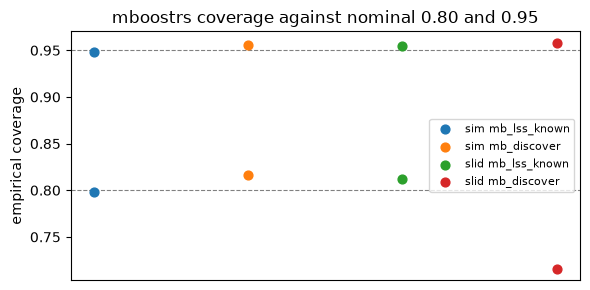

In [11]:
fig, ax = plt.subplots(figsize=(6, 3))
x = np.arange(2)
groups = [("sim", "mb_lss_known"), ("sim", "mb_discover"),
          ("slid", "mb_lss_known"), ("slid", "mb_discover")]
for i, (arm, m) in enumerate(groups):
    d = res.filter((pl.col("arm") == arm) & (pl.col("method") == m))
    ax.scatter([0.02 * i + 0.01] * 2,
               [d["coverage80"].mean(), d["coverage95"].mean()],
               label=f"{arm} {m}", s=40, zorder=3)
ax.axhline(0.80, color="grey", ls="--", lw=0.8)
ax.axhline(0.95, color="grey", ls="--", lw=0.8)
ax.set_xticks([])
ax.set_ylabel("empirical coverage")
ax.set_title("mboostrs coverage against nominal 0.80 and 0.95")
ax.legend(fontsize=8, loc="center right")
plt.tight_layout()
plt.show()

The known specification is well calibrated on both arms: 95% coverage 0.948 on
`sim` and 0.955 on `slid`, each within a couple of standard errors of nominal,
and the 80% interval is close too. Discovery is calibrated on `sim` (0.956 at
95%) but undercovers on `slid`: the 80% interval covers 0.716 of test rows. That
is the same intercept-only model again — a constant mean plus a band derived
from a model that never found the `age` and `education` signal, so it is too
narrow where the true spread is large and too wide where it is small.

## Iteration speed

Wall-clock seconds per fit and per drop-one-covariate what-if refit. Medians are
used because one CatBoost fit recorded 3404 s against a 0.76 s median, an outlier that does not reflect the typical cost.

In [12]:
tim = []
for arm in ("sim", "slid"):
    d5 = ev["arms"][arm]["d5"]
    for m, r in d5.items():
        tim.append({"arm": arm, "method": m,
                    "fit_median_s": round(r["fit_median"], 3),
                    "fit_p90_s": round(r["fit_p90"], 3),
                    "whatif_median_s": round(r.get("whatif_median", float("nan")), 3)})
tim_tbl = pl.DataFrame(tim).sort(["arm", "fit_median_s"])
tim_tbl

arm,method,fit_median_s,fit_p90_s,whatif_median_s
str,str,f64,f64,f64
"""sim""","""statsmodels_gamlss_known""",0.025,0.545,0.025
"""sim""","""xgboost""",0.062,0.098,0.054
"""sim""","""statsmodels_2stage""",0.095,0.137,0.082
"""sim""","""lightgbm""",0.116,0.282,0.061
"""sim""","""histgb""",0.193,0.529,0.185
…,…,…,…,…
"""slid""","""catboost_uncertainty""",0.407,0.434,0.383
"""slid""","""aplr""",0.857,0.966,0.705
"""slid""","""catboost_quantile""",1.265,1.46,1.199


The known-specification LSS fit is the cheapest of the accurate methods: about
0.28 s per fit on `sim` and 0.12 s on `slid`, with drop-one refits under 0.25 s.
The discovery path is roughly ten times slower (3.3 s and 1.8 s per fit) because
it runs several cross-validated screens plus an LSS tuning stage. The classical spline model is faster still, and the
tree ensembles are comparable; the slower methods are APLR, EBM and the
quantile CatBoost fits.

(what-the-scorecard-records)=
## Scorecard profile

Only the dimensions this study measures are scored. The rest are left
`unmeasured`; no aggregate is formed.

D1a is prescribed-specification recovery, D1b is discovery from data alone, D5 is iteration speed, D9 is calibration and D11 is predictive validity. Anchor 4 is the rubric level above 3; it asks for recovery across several structure types and for small-sample and extrapolation coverage.

In [13]:
pl.DataFrame([{"dimension": d["id"], "name": d["name"],
               "score": d["score"], "status": d["status"]}
              for d in sc["dimensions"]])

dimension,name,score,status
str,str,i64,str
"""D1a""","""Relationship recovery under a …",3,"""scored"""
"""D1b""","""Relationship discovery from da…",3,"""scored"""
"""D2""","""Causal humility and support""",null,"""unmeasured"""
"""D3""","""Explanation quality""",null,"""unmeasured"""
"""D4""","""Importance quantification""",null,"""unmeasured"""
…,…,…,…
"""D7""","""Human-friendliness""",null,"""unmeasured"""
"""D8""","""Agent-friendliness""",null,"""unmeasured"""
"""D9""","""Uncertainty honesty (calibrati…",3,"""scored"""


On `sim`, both mboostrs tracks have lower CRPS than the per-seed best data-only
competitor. On `slid`, the known Gaussian specification is close to that reference,
while discovery chooses Gamma and returns an intercept-only model. The resulting
higher CRPS and lower 80% coverage motivate the second evaluation below, which uses a branch with family validation.

## Second evaluation with the combined branch

The second evaluation uses a combined branch with five changes to the discovery path,
including family validation. The protocol is identical
to the baseline: the same two arms, the same ten seeds, the same tracks and the
same competitor field. Only the mboostrs rows were refit; the 220 competitor
rows are reused byte-for-byte from the baseline file, so every gap here is
paired on exactly the same test splits.

The artefacts of the second evaluation are in `slid_lss_sim/rerun_combined/` and are scored with
the same scorecard (`analyze.py`, `mboostrs-scorecard/2.1`). 


In [14]:
RR = STUDY / "rerun_combined"
rres = pl.read_parquet(RR / "results.parquet")
rev = json.loads((RR / "evidence.json").read_text())
rsc = json.loads((RR / "scores.json").read_text())
rprov = json.loads((RR / "provenance.json").read_text())
deltas = json.loads((RR / "deltas.json").read_text())
selections = json.loads((RR / "slid_discovery_selections.json").read_text())

print("rerun rows:", rres.height,
      "| fresh mboostrs rows:", rprov["mboostrs_rows_fresh"],
      "| reused competitor rows:", rprov["competitor_rows_reused"])
print("combined commit:", rprov["mboostrs_combined_commit_sha"])
print("mboostrs file:", rprov["mboostrs_file"])

rerun rows: 260 | fresh mboostrs rows: 40 | reused competitor rows: 220
combined commit: e79fa6140ee013e1f024b4fc296b0deabc1712ca
mboostrs file: /workspace/agent-test/bench4/site-combined/mboostrs/__init__.py


(the-one-large-move)=
### Paired loss changes

The gap to the per-seed best competitor for the baseline and updated discovery pipelines on the same splits.
Negative is better; `SE` is the standard error of the gap in the updated evaluation.


In [15]:
head_rows = []
for t in deltas["tracks"]:
    h = deltas["headline"][t]
    c, r = h["crps_gap_pct"], h["rmse_gap_pct"]
    head_rows.append({
        "track": t,
        "crps_before": round(c["baseline"], 2), "crps_after": round(c["combined"], 2),
        "crps_delta": round(c["delta"], 2), "crps_se_after": round(c["combined_se"], 2),
        "rmse_before": round(r["baseline"], 2), "rmse_after": round(r["combined"], 2),
        "rmse_delta": round(r["delta"], 2), "rmse_se_after": round(r["combined_se"], 2)})
pl.DataFrame(head_rows)

track,crps_before,crps_after,crps_delta,crps_se_after,rmse_before,rmse_after,rmse_delta,rmse_se_after
str,f64,f64,f64,f64,f64,f64,f64,f64
"""sim_known""",-4.56,-4.56,0.0,0.16,-1.02,-1.02,0.0,0.14
"""sim_discovery""",-4.44,-4.44,0.0,0.16,-0.99,-0.99,0.0,0.14
"""slid_known""",0.58,0.58,0.0,0.13,0.75,0.75,0.0,0.13
"""slid_discovery""",34.07,1.15,-32.92,0.17,28.76,0.85,-27.91,0.15


Both `sim` tracks have 0.00 pp change in both losses. The `slid` known-specification
result is also unchanged. For `slid` discovery, the CRPS gap falls from
**+34.07% to +1.15%** (change -32.92 pp, SE 0.17) and the RMSE gap from
**+28.76% to +0.85%** (change -27.91 pp, SE 0.15). Discovery on `slid` remains behind the per-seed best competitor; both gaps
are larger than their reported standard errors.


(what-discovery-now-selects-on-the-real-arm)=
### Selected SLID formulas

The second evaluation records what the combined discovery path chooses on each `slid` split.


In [16]:
sel = pl.DataFrame([
    {"seed": r["seed"], "family": r["family"], "formula": r["formula"],
     "spread_formula": r["spread_formula"],
     "loc_terms": ", ".join(r["loc_terms"])}
    for r in selections["rows"]])
sel

seed,family,formula,spread_formula,loc_terms
i64,str,str,str,str
0,"""Gaussian""","""bbs(education, df=4.0) + bbs(a…",null,"""age, age:sex, education, sex"""
1,"""Gaussian""","""bbs(education, df=4.0) + bbs(a…",null,"""age, age:sex, education, sex"""
2,"""Gaussian""","""bbs(education, df=4.0) + bbs(a…",null,"""age, education, sex"""
3,"""Gaussian""","""bbs(education, df=4.0) + bbs(a…",null,"""age, age:sex, education, sex"""
4,"""Gaussian""","""bbs(education, df=4.0) + bbs(a…",null,"""age, age:sex, education, sex"""
5,"""Gaussian""","""bbs(education, df=4.0) + bbs(a…",null,"""age, age:sex, education, sex"""
6,"""Gaussian""","""bbs(education, df=4.0) + bbs(a…",null,"""age, education, sex"""
7,"""Gaussian""","""bbs(education, df=4.0) + bbs(a…",null,"""age, education, sex"""
8,"""Gaussian""","""bbs(education, df=4.0) + bbs(a…",null,"""age, age:sex, education, sex"""


In [17]:
print("families:", selections["family_all_seeds"])
sel.group_by("formula").len().sort("len", descending=True)

families: ['Gaussian']


formula,len
str,u32
"""bbs(education, df=4.0) + bbs(a…",7
"""bbs(education, df=4.0) + bbs(a…",3


Discovery infers **Gaussian** on all ten seeds and returns a non-empty
location model on all ten. The recovered formula is
`bbs(education) + bbs(age) + bols(sex)` with the `bbs(age, by=sex)` interaction
on seven seeds and without it on three. That is close to the Gaussian override
the study's literature specification uses
(`bbs(education) + bbs(age) + bols(sex) + bbs(age, by=sex)`).

Two specification differences may contribute to the residual gap. First, discovery never
selects `language`, which the known specification includes. Second, the spread
model is empty on nine of ten seeds (`spread_formula` is `None`), so discovery
fits a constant scale while the known specification has an `age` and `sex`
spread model. Those two omissions are the plausible source of the ~0.6 pp that
still separates discovery from the known specification on `slid`.


### The scorecard dimensions

The same five dimensions the study measures, with the metric behind each and its
value in the baseline and in the second evaluation. Anchors are unchanged because the evidence changed and the rubric that grades it did not.


In [18]:
dim_rows = []
for r in deltas["rows"]:
    if r["status"] != "measured":
        continue
    pm = r["primary_metric"]
    m = r["metrics"][pm]
    dim_rows.append({
        "dim": r["dimension"], "track": r["track"], "metric": pm,
        "before": m.get("baseline"), "after": m.get("combined"),
        "delta": m.get("delta"),
        "score": f"{r['score_baseline']} -> {r['score_combined']}"})
pl.DataFrame(dim_rows)

dim,track,metric,before,after,delta,score
str,str,str,f64,f64,f64,str
"""D1a""","""sim_known""","""mb_lss_known.rmse_mu""",0.056252,0.056252,0.0,"""3 -> 3"""
"""D1b""","""sim_discovery""","""loc_precision""",0.98,0.98,0.0,"""3 -> 3"""
"""D5""","""sim_known""","""fit_median""",0.279213,0.264357,-0.014856,"""3 -> 3"""
"""D5""","""sim_discovery""","""fit_median""",3.341083,3.224794,-0.116289,"""3 -> 3"""
"""D5""","""slid_known""","""fit_median""",0.119009,0.139634,0.020626,"""3 -> 3"""
…,…,…,…,…,…,…
"""D9""","""slid_discovery""","""coverage80_gap_pp""",-8.40558,0.36871,8.77429,"""3 -> 3"""
"""D11""","""sim_known""","""crps_gap_pct""",-4.555032,-4.555032,0.0,"""3 -> 3"""
"""D11""","""sim_discovery""","""crps_gap_pct""",-4.441754,-4.441754,0.0,"""3 -> 3"""


**D1a — prescribed-specification recovery.** Unchanged. The changes are in the discovery path. RMSE of the mean and of the log-scale are unchanged to three decimals.

**D1b — discovery from data alone.** The `sim` selection is unchanged (location precision 0.98, recall 1.00, scale precision and recall 1.00, zero false discoveries and zero traps, Gaussian and the interaction in 10/10). On the real arm, discovery returns a non-empty location model on every seed. The anchor stays at 3 because anchor 4 asks for published recovery rates across several structure types and this study still rests on a single planted-truth DGP family.

**D5 — iteration speed.** The largest difference is on `slid` discovery, where the median fit drops from 1.84 s to 1.14 s and a drop-one what-if from 1.11 s to 0.67 s, because the Gaussian family converges faster than the Gamma family.

**D9 — calibration.** The other arm/track coverage results are unchanged. `slid` discovery undercovers in the baseline: 80% coverage is 0.716 (a -8.41 pp gap) with the intercept-only model. In the second evaluation it is 0.804 (a +0.37 pp gap, SE 0.47), and 95% coverage is 0.950 (-0.01 pp), against 0.958 (+0.83 pp) in the baseline. The remaining 80% gap is small and not significantly different from nominal at ten seeds. Anchor 4 is still not assigned: small-n and extrapolation adaptation are not measured.

**D11 — predictive validity.** `sim` known -4.56%, `sim` discovery -4.44%, `slid` known +0.58%, all unchanged. `slid` discovery moves from +34.07% to +1.15% CRPS. Anchor 4 is not assigned because comparator settings are untuned and the best competitor is chosen retrospectively per seed, so the field is not a matched-budget comparison.


### Calibration across discovery configurations


In [19]:
cov_rows = []
for arm in ("sim", "slid"):
    for meth, lab in (("mb_lss_known", "known"), ("mb_discover", "discovery")):
        b = ev["arms"][arm]["coverage"][meth]
        c = rev["arms"][arm]["coverage"][meth]
        cov_rows.append({
            "arm": arm, "track": lab,
            "cov80_before": round(b["coverage80"]["mean"], 3),
            "cov80_after": round(c["coverage80"]["mean"], 3),
            "cov95_before": round(b["coverage95"]["mean"], 3),
            "cov95_after": round(c["coverage95"]["mean"], 3)})
pl.DataFrame(cov_rows)

arm,track,cov80_before,cov80_after,cov95_before,cov95_after
str,str,f64,f64,f64,f64
"""sim""","""known""",0.798,0.798,0.948,0.948
"""sim""","""discovery""",0.816,0.816,0.956,0.956
"""slid""","""known""",0.812,0.812,0.955,0.955
"""slid""","""discovery""",0.716,0.804,0.958,0.95


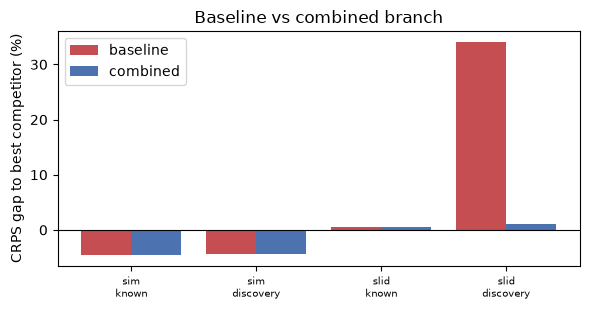

In [20]:
fig, ax = plt.subplots(figsize=(6, 3.2))
tracks = ["sim_known", "sim_discovery", "slid_known", "slid_discovery"]
before = [deltas["headline"][t]["crps_gap_pct"]["baseline"] for t in tracks]
after = [deltas["headline"][t]["crps_gap_pct"]["combined"] for t in tracks]
x = np.arange(len(tracks))
ax.bar(x - 0.2, before, 0.4, label="baseline", color="#c44e52")
ax.bar(x + 0.2, after, 0.4, label="combined", color="#4c72b0")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels([t.replace("_", "\n") for t in tracks], fontsize=7)
ax.set_ylabel("CRPS gap to best competitor (%)")
ax.set_title("Baseline vs combined branch")
ax.legend()
plt.tight_layout()
plt.show()

(what-this-rerun-does-and-does-not-establish)=
### Second evaluation: interpretation and limitations

The second evaluation uses the baseline test splits and changes only the mboostrs build.
On `slid`, discovery now selects Gaussian and non-empty mean formulas, reduces
CRPS and RMSE gaps, and has coverage close to nominal. The `sim` results are
unchanged. These measurements do not establish that the selected `slid` model
is the true conditional distribution.

It does not establish a win on `slid`. Discovery at +1.15% (SE 0.17) is still
behind the best data-only competitor, and the known specification at +0.58% was
already not ahead. It does not move any anchor to 4, because the conditions the
rubric attaches to anchor 4 (several task families or structure types under
matched budgets, small-n and extrapolation coverage) are outside what this study
runs. The competitor field is also reused from the baseline and unchanged, so
the comparison tests only the library's own change.


### Open limitations


In [21]:
pl.DataFrame([
    {"id": f["id"], "friction": f["title"], "status": f["status"],
     "fix": f"#{f['fix_pr']}" if f["fix_pr"] else "open"}
    for f in deltas["friction"]])

id,friction,status,fix
i64,str,str,str
1,"""no high-level mb.fit discovery…","""open""","""open"""
2,"""DiscoveryResult has no fitted …","""resolved""","""#589"""
3,"""discover treats every non-resp…","""resolved""","""#590"""
4,"""discover silent on an intercep…","""resolved""","""#586"""
5,"""family probe off by default in…","""resolved""","""#585"""
6,"""cvrisk_gamboostLSS(folds=int) …","""resolved""","""#587"""
7,"""with_mstop predictions disagre…","""open""","""open"""
8,"""build_info git_revision is che…","""open""","""open"""
9,"""brandom(language) fold warning…","""open""","""open"""


The library limitations that remain open are: no high-level discovery entry point, a disagreement in the `with_mstop` refit, a misleading `build_info()["git_revision"]`, a confusing `brandom` fold warning, and a single uncertainty setting in `discover`.
